In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [1]:
#Load data and set regimes
import pandas as pd
import numpy as np
from arch import arch_model

# Load Excel and rename columns
df = pd.read_excel(DATA / "data.xlsx", skiprows=2)
df = df[['Dates', 'SPX Index', 'VIX Index', 'CAC Index']]
df.columns = ['Date', 'SPX Index', 'VIX Index', 'CAC Index']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')


# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

def assign_regime(date):
    for start, end, regime in regime_periods:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end):
            return regime
    return "Unclassified"

df['Regime'] = df['Date'].apply(assign_regime)


In [ ]:
df['SPX Return'] = np.log(df['SPX Index']).diff() * 100
df['CAC Return'] = np.log(df['CAC Index']).diff() * 100
df = df.dropna(subset=['SPX Return', 'CAC Return'])

# Prepare to collect results
spx_results = []
cac_results = []

for start, end, label in regime_periods:
    mask = (df['Date'] >= pd.Timestamp(start)) & (df['Date'] <= pd.Timestamp(end))
    spx_ret = df.loc[mask, 'SPX Return'].dropna()
    cac_ret = df.loc[mask, 'CAC Return'].dropna()

    if len(spx_ret) < 100 or len(cac_ret) < 100:
        print(f"Skipping {label} ({start}–{end}) — insufficient data.")
        continue

    # ARCH(1) for SPX
    spx_fit = arch_model(spx_ret, vol='ARCH', p=1, mean='Constant', dist='normal', rescale=False).fit(disp='off')
    spx_vol = spx_fit.conditional_volatility

    spx_params = spx_fit.params
    spx_results.append({
        'Regime': label,
        'Start': start,
        'End': end,
        'mu': spx_params.get('mu'),
        'alpha0': spx_params.get('omega'),
        'alpha1': spx_params.get('alpha[1]')
    })

    # ARCH(1) for CAC
    cac_fit = arch_model(cac_ret, vol='ARCH', p=1, mean='Constant', dist='normal', rescale=False).fit(disp='off')
    cac_vol = cac_fit.conditional_volatility
    
    cac_params = cac_fit.params
    cac_results.append({
        'Regime': label,
        'Start': start,
        'End': end,
        'mu': cac_params.get('mu'),
        'alpha0': cac_params.get('omega'),
        'alpha1': cac_params.get('alpha[1]')
    })


# Build DataFrame
spx_df = pd.DataFrame(spx_results).add_suffix('_SPX')
cac_df = pd.DataFrame(cac_results).add_suffix('_CAC')

# Merge on Regime + Period
comparison_df = spx_df.merge(
    cac_df,
    left_on=["Regime_SPX", "Start_SPX", "End_SPX"],
    right_on=["Regime_CAC", "Start_CAC", "End_CAC"]
)

# Clean and select columns
comparison_df['Regime'] = comparison_df['Regime_SPX']
comparison_df = comparison_df[[
    'Regime', 'mu_SPX', 'alpha0_SPX', 'alpha1_SPX',
    'mu_CAC', 'alpha0_CAC', 'alpha1_CAC'
]].round(4)

# Display comparison table
print("\n=== ARCH(1) Parameter Comparison: SPX vs CAC by Regime ===\n")
print(comparison_df.to_string(index=False))

Skipping Crisis (2020-02-18–2020-03-24) — insufficient data.
Skipping Stability (2025-01-01–2025-02-20) — insufficient data.
Skipping Crisis (2025-02-20–2025-04-30) — insufficient data.

=== ARCH(1) Parameter Comparison: SPX vs CAC by Regime ===

   Regime  mu_SPX  alpha0_SPX  alpha1_SPX  mu_CAC  alpha0_CAC  alpha1_CAC
Stability  0.0586      0.6823      0.1944  0.0598      1.2950      0.1509
   Crisis -0.0759      1.7177      0.1716 -0.1249      2.8404      0.1072
 Recovery  0.0715      1.0546      0.2022  0.0437      1.9468      0.2970
Stability  0.0356      0.4990      0.0402  0.0569      0.6891      0.1310
   Crisis -0.1550      4.7385      0.2275 -0.1897      4.1806      0.3100
 Recovery  0.1037      1.4599      0.0000  0.0843      1.8415      0.1371
Stability  0.0546      0.6109      0.2538  0.0312      1.0497      0.2916
 Recovery  0.2044      0.8333      0.6759  0.1088      1.6797      0.0514
Stability  0.0917      0.6093      0.2424  0.1190      0.9442      0.1456
   Crisis -0.

In [3]:
import plotly.express as px
import pandas as pd

# Step 1: Loop over unique regimes
for regime in comparison_df['Regime'].unique():
    sub = comparison_df[comparison_df['Regime'] == regime]

    # Skip if < than 2 samples
    if len(sub) < 2:
        print(f"Skipping regime: {regime} — not enough data for correlation")
        continue

    # Step 2: Select relevant parameters
    param_cols = ['mu_SPX', 'alpha0_SPX', 'alpha1_SPX', 'mu_CAC', 'alpha0_CAC', 'alpha1_CAC']
    corr = sub[param_cols].corr().loc[
        ['mu_SPX', 'alpha0_SPX', 'alpha1_SPX'],
        ['mu_CAC', 'alpha0_CAC', 'alpha1_CAC']
    ].round(3)

    # Step 3: Plot
    fig = px.imshow(
        corr,
        text_auto=True,
        labels=dict(x="CAC Parameters", y="SPX Parameters", color="Correlation"),
        title=f"ARCH(1) Parameter Correlation: SPX vs CAC — {regime} Regime"
    )
    fig.update_layout(font=dict(size=14), width=1000, height=400)
    fig.show()


In [4]:
from arch import arch_model
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

regime_vol_corrs = []

# === Fit ARCH(1) models and compute volatility correlation per period ===
for start, end, label in regime_periods:
    mask = (df['Date'] >= pd.to_datetime(start)) & (df['Date'] <= pd.to_datetime(end))
    subset = df.loc[mask].copy()
    
    if len(subset) < 100:
        print(f"Skipping {label} {start}–{end} — too short.")
        continue

    # Fit SPX ARCH(1)
    spx_fit = arch_model(subset['SPX Return'], vol='ARCH', p=1, mean='Constant', dist='normal').fit(disp='off')
    spx_vol = spx_fit.conditional_volatility

    # Fit CAC ARCH(1)
    cac_fit = arch_model(subset['CAC Return'], vol='ARCH', p=1, mean='Constant', dist='normal').fit(disp='off')
    cac_vol = cac_fit.conditional_volatility

    # Ensure same length and index alignment
    if len(spx_vol) != len(cac_vol):
        print(f"Length mismatch in {label} {start}–{end}, skipping.")
        continue

    # Compute correlation
    corr, _ = pearsonr(spx_vol, cac_vol)

    regime_vol_corrs.append({
        "Regime": label,
        "Start": start,
        "End": end,
        "Vol_Corr": round(corr, 4)
    })

# === Convert to DataFrame and display ===
vol_corr_df = pd.DataFrame(regime_vol_corrs)
print("\n=== Volatility Correlation Between SPX and CAC (ARCH(1)) ===\n")
print(vol_corr_df.to_string(index=False))



/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_1396/1603557351.py:31: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.

/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_1396/1603557351.py:31: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



Skipping Crisis 2020-02-18–2020-03-24 — too short.
Skipping Stability 2025-01-01–2025-02-20 — too short.
Skipping Crisis 2025-02-20–2025-04-30 — too short.

=== Volatility Correlation Between SPX and CAC (ARCH(1)) ===

   Regime      Start        End  Vol_Corr
Stability 1990-01-01 2000-03-31    0.2981
   Crisis 2000-04-01 2002-09-30    0.4303
 Recovery 2002-10-01 2004-03-31    0.5977
Stability 2004-04-01 2007-10-31    0.3909
   Crisis 2007-11-01 2009-03-31    0.5350
 Recovery 2009-04-01 2010-12-31       NaN
Stability 2011-01-01 2020-02-17    0.5272
 Recovery 2020-03-25 2021-09-15    0.4795
Stability 2020-09-16 2021-12-31    0.3493
   Crisis 2022-01-01 2022-10-12       NaN
 Recovery 2022-10-13 2023-07-31    0.2104
Stability 2023-08-01 2024-12-31    0.1601


In [5]:
#For DAX Index

import pandas as pd
import numpy as np
from arch import arch_model

# === Load and rename ===
df = pd.read_excel(DATA / "data.xlsx", skiprows=2)
df = df[['Dates', 'SPX Index', 'DAX Index']]
df.columns = ['Date', 'SPX Index', 'DAX Index']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')

# === Compute log returns ===
df['SPX Return'] = np.log(df['SPX Index']).diff() * 100
df['DAX Return'] = np.log(df['DAX Index']).diff() * 100
df = df.dropna()

# === Define regime periods ===
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

spx_results, dax_results = [], []

for start, end, label in regime_periods:
    mask = (df['Date'] >= pd.Timestamp(start)) & (df['Date'] <= pd.Timestamp(end))
    spx_ret = df.loc[mask, 'SPX Return']
    dax_ret = df.loc[mask, 'DAX Return']

    if len(spx_ret) < 100 or len(dax_ret) < 100:
        print(f"Skipping {label} {start}–{end} — not enough data.")
        continue

    # ARCH(1) for SPX
    spx_fit = arch_model(spx_ret, vol='ARCH', p=1, mean='Constant', dist='normal').fit(disp='off')
    spx_results.append({
        "Regime": label, "Start": start, "End": end,
        "mu": spx_fit.params.get("mu"),
        "alpha0": spx_fit.params.get("omega"),
        "alpha1": spx_fit.params.get("alpha[1]")
    })

    # ARCH(1) for DAX
    dax_fit = arch_model(dax_ret, vol='ARCH', p=1, mean='Constant', dist='normal').fit(disp='off')
    dax_results.append({
        "Regime": label, "Start": start, "End": end,
        "mu": dax_fit.params.get("mu"),
        "alpha0": dax_fit.params.get("omega"),
        "alpha1": dax_fit.params.get("alpha[1]")
    })

import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook"

# Build DataFrame
spx_df = pd.DataFrame(spx_results).add_suffix('_SPX')
dax_df = pd.DataFrame(dax_results).add_suffix('_DAX')

# Merge on Regime + Period
comparison_df = spx_df.merge(
    dax_df,
    left_on=["Regime_SPX", "Start_SPX", "End_SPX"],
    right_on=["Regime_DAX", "Start_DAX", "End_DAX"]
)

# Clean and select columns
comparison_df['Regime'] = comparison_df['Regime_SPX']
comparison_df = comparison_df[[
    'Regime', 'mu_SPX', 'alpha0_SPX', 'alpha1_SPX',
    'mu_DAX', 'alpha0_DAX', 'alpha1_DAX'
]].round(4)

# Display comparison table
print("\n=== ARCH(1) Parameter Comparison: SPX vs DAX by Regime ===\n")
print(comparison_df.to_string(index=False))

import plotly.express as px
import pandas as pd

# Expected structure of comparison_df:
# ['Regime', 'mu_SPX', 'alpha0_SPX', 'alpha1_SPX', 'mu_DAX', 'alpha0_DAX', 'alpha1_DAX']

# Step 1: Loop over each regime
for regime in comparison_df['Regime'].unique():
    sub = comparison_df[comparison_df['Regime'] == regime]

    if len(sub) < 2:
        print(f"Skipping regime: {regime} — not enough samples for correlation.")
        continue

    # Step 2: Extract relevant parameters
    param_cols = ['mu_SPX', 'alpha0_SPX', 'alpha1_SPX', 'mu_DAX', 'alpha0_DAX', 'alpha1_DAX']
    corr = sub[param_cols].corr().loc[
        ['mu_SPX', 'alpha0_SPX', 'alpha1_SPX'],
        ['mu_DAX', 'alpha0_DAX', 'alpha1_DAX']
    ].round(3)

    # Step 3: Plot heatmap
    fig = px.imshow(
        corr,
        text_auto=True,
        labels=dict(x="DAX Parameters", y="SPX Parameters", color="Correlation"),
        title=f"ARCH(1) Parameter Correlation: SPX vs DAX — {regime} Regime"
    )
    fig.update_layout(font=dict(size=14), width=1000, height=400)
    fig.show()


Skipping Crisis 2020-02-18–2020-03-24 — not enough data.
Skipping Stability 2025-01-01–2025-02-20 — not enough data.
Skipping Crisis 2025-02-20–2025-04-30 — not enough data.

=== ARCH(1) Parameter Comparison: SPX vs DAX by Regime ===

   Regime  mu_SPX  alpha0_SPX  alpha1_SPX  mu_DAX  alpha0_DAX  alpha1_DAX
Stability  0.0586      0.6823      0.1944  0.0798      1.2532      0.2473
   Crisis -0.0759      1.7177      0.1716 -0.1338      2.9516      0.2108
 Recovery  0.0715      1.0546      0.2022  0.1049      3.5157      0.1783
Stability  0.0356      0.4990      0.0402  0.0839      0.7713      0.0982
   Crisis -0.1550      4.7385      0.2275 -0.1307      3.8952      0.3204
 Recovery  0.1037      1.4599      0.0000  0.1199      1.7788      0.0000
Stability  0.0546      0.6109      0.2538  0.0549      1.1007      0.2342
 Recovery  0.2044      0.8333      0.6759  0.1264      1.8446      0.0046
Stability  0.0917      0.6093      0.2424  0.0612      0.9184      0.2115
   Crisis -0.1472      2.

In [6]:
#FOR SPX and AAPl

df = pd.read_excel(DATA / "data_stocks.xlsx", skiprows=2)
df = df[['Dates', 'SPX Index', 'AAPL']]
df.columns = ['Date', 'SPX Index', 'AAPL']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')

# === Compute log returns ===
df['SPX Return'] = np.log(df['SPX Index']).diff() * 100
df['AAPL Return'] = np.log(df['AAPL']).diff() * 100
df = df.dropna()

# === Define regime periods ===
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

spx_results, aapl_results = [], []

for start, end, label in regime_periods:
    mask = (df['Date'] >= pd.Timestamp(start)) & (df['Date'] <= pd.Timestamp(end))
    spx_ret = df.loc[mask, 'SPX Return']
    aapl_ret = df.loc[mask, 'AAPL Return']

    if len(spx_ret) < 100 or len(aapl_ret) < 100:
        print(f"Skipping {label} {start}–{end} — not enough data.")
        continue

    # ARCH(1) for SPX
    spx_fit = arch_model(spx_ret, vol='ARCH', p=1, mean='Constant', dist='normal').fit(disp='off')
    spx_results.append({
        "Regime": label, "Start": start, "End": end,
        "mu": spx_fit.params.get("mu"),
        "alpha0": spx_fit.params.get("omega"),
        "alpha1": spx_fit.params.get("alpha[1]")
    })

    # ARCH(1) for DAX
    aapl_fit = arch_model(aapl_ret, vol='ARCH', p=1, mean='Constant', dist='normal').fit(disp='off')
    aapl_results.append({
        "Regime": label, "Start": start, "End": end,
        "mu": aapl_fit.params.get("mu"),
        "alpha0": aapl_fit.params.get("omega"),
        "alpha1": aapl_fit.params.get("alpha[1]")
    })

import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook"

# Build DataFrame
spx_df = pd.DataFrame(spx_results).add_suffix('_SPX')
aapl_df = pd.DataFrame(aapl_results).add_suffix('_AAPL')

# Merge on Regime + Period
comparison_df = spx_df.merge(
    aapl_df,
    left_on=["Regime_SPX", "Start_SPX", "End_SPX"],
    right_on=["Regime_AAPL", "Start_AAPL", "End_AAPL"]
)

# Clean and select columns
comparison_df['Regime'] = comparison_df['Regime_SPX']
comparison_df = comparison_df[[
    'Regime', 'mu_SPX', 'alpha0_SPX', 'alpha1_SPX',
    'mu_AAPL', 'alpha0_AAPL', 'alpha1_AAPL'
]].round(4)

# Display comparison table
print("\n=== ARCH(1) Parameter Comparison: SPX vs AAPL, underlying stock by Regime ===\n")
print(comparison_df.to_string(index=False))

import plotly.express as px
import pandas as pd

# Expected structure of comparison_df:
# ['Regime', 'mu_SPX', 'alpha0_SPX', 'alpha1_SPX', 'mu_DAX', 'alpha0_DAX', 'alpha1_DAX']

# Step 1: Loop over each regime
for regime in comparison_df['Regime'].unique():
    sub = comparison_df[comparison_df['Regime'] == regime]

    if len(sub) < 2:
        print(f"Skipping regime: {regime} — not enough samples for correlation.")
        continue

    # Step 2: Extract relevant parameters
    param_cols = ['mu_SPX', 'alpha0_SPX', 'alpha1_SPX', 'mu_AAPL', 'alpha0_AAPL', 'alpha1_AAPL']
    corr = sub[param_cols].corr().loc[
        ['mu_SPX', 'alpha0_SPX', 'alpha1_SPX'],
        ['mu_AAPL', 'alpha0_AAPL', 'alpha1_AAPL']
    ].round(3)

    # Step 3: Plot heatmap
    fig = px.imshow(
        corr,
        text_auto=True,
        labels=dict(x="AAPL Parameters", y="SPX Parameters", color="Correlation"),
        title=f"ARCH(1) Parameter Correlation: SPX vs AAPL — {regime} Regime"
    )
    fig.update_layout(font=dict(size=14), width=1000, height=400)
    fig.show()

Skipping Crisis 2020-02-18–2020-03-24 — not enough data.
Skipping Stability 2025-01-01–2025-02-20 — not enough data.
Skipping Crisis 2025-02-20–2025-04-30 — not enough data.

=== ARCH(1) Parameter Comparison: SPX vs AAPL, underlying stock by Regime ===

   Regime  mu_SPX  alpha0_SPX  alpha1_SPX  mu_AAPL  alpha0_AAPL  alpha1_AAPL
Stability  0.0586      0.6823      0.1944   0.0515       9.0555       0.1526
   Crisis -0.0759      1.7177      0.1716  -0.1382      10.3855       0.7224
 Recovery  0.0715      1.0546      0.2022   0.1331       5.2270       0.0316
Stability  0.0356      0.4990      0.0402   0.3097       5.2811       0.1163
   Crisis -0.1550      4.7385      0.2275  -0.1168       9.5290       0.2127
 Recovery  0.1037      1.4599      0.0000   0.2590       2.4161       0.1311
Stability  0.0546      0.6109      0.2538   0.1091       2.2416       0.1792
 Recovery  0.2044      0.8333      0.6759   0.2264       3.8447       0.0738
Stability  0.0917      0.6093      0.2424   0.1126   

In [7]:
df = pd.read_excel(DATA / "data_stocks.xlsx", skiprows=2)
#df = df[['Dates', 'SPX Index', 'AAPL Index']]
#df.columns = ['Date', 'SPX Index', 'AAPL Index']
#df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
#df = df.sort_values('Date')

df

,Dates,AAPL,SPX Index,AMZN,GOOGL,JPM,MSFT
0,2025-04-24,208.097107,5416.65,186.539993,159.087402,244.639999,386.590271
1,2025-04-23,204.332062,5375.86,180.600006,155.162170,240.880005,373.703949
2,2025-04-22,199.478424,5287.76,173.179993,151.286850,235.589996,366.147827
3,2025-04-21,192.907028,5158.20,167.320007,147.491440,228.990005,358.461914
4,2025-04-17,196.722031,5282.70,172.610001,150.977234,231.960007,367.106049
...,...,...,...,...,...,...,...
8889,NaT,NaN,NaN,NaN,NaN,3.389648,0.387385
8890,NaT,NaN,NaN,NaN,NaN,3.389648,0.381532
8891,NaT,NaN,NaN,NaN,NaN,3.376090,0.391110
8892,NaT,NaN,NaN,NaN,NaN,3.362532,0.379936


In [8]:
import yfinance as yf
import pandas as pd

#Importing data and trying to format it as data

# === Step 1: Download adjusted close prices ===
tickers = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM']
data = yf.download(tickers, start="1990-01-01", end="2025-04-30", auto_adjust=True)

# === Step 2: Flatten column index if needed ===
if isinstance(data.columns, pd.MultiIndex):
    data = data.droplevel(0, axis=1)

# === Step 3: Rename columns
data.columns = [f"{ticker}" for ticker in data.columns]

# === Step 4: Reset index (Date column still datetime)
data = data.reset_index()

# === ✅ Step 5: Sort DESCENDING based on datetime BEFORE converting to string
data = data.sort_values("Date", ascending=False)

# === Step 6: Convert to "DD/MM/YYYY" format AFTER sorting
data["Date"] = data["Date"].dt.strftime('%d/%m/%Y')

# === Step 7: Add "Equity" metadata row
meta_row = ['Equity'] * data.shape[1]
meta_df = pd.DataFrame([meta_row], columns=data.columns)

# === Step 8: Combine and save
final_df = pd.concat([meta_df, data], ignore_index=True)
final_df.to_excel(DATA / "spx_stocks_clean.xlsx", index=False)







[*********************100%***********************]  5 of 5 completed


### DISCU RAPHAEL:

corrélations par régime entre les retours sur des actifs d'un indice

fit garch pr max log vraisemblance --> vol par régime, et on divise les rendements par la vol par régime
--> regarder les corrélations par rendements

dans un GARCH ou ARCH multivarié on spécifie une matrice de corrélation des innovations (innovation = eta), 
donc quand tu regardes les corrélations de tes rendements tu regardes corr(sigma_t*eta_t), 
donc un truc intéressant peut être de prendre tes rendements standardisés (divisés par la vol)

DISCU LOUIS:

vol sur tout la data en differenciant param par régimes prédéfinis (comme si transition matrix remplie de 1 et de 0, vu que on connais quand quel régime)
faire avec indice sous jacent a SPX
demander data set à Louis


A LIRE : 
Maheu et Liu en 2023
Maheu et mc cordy 2000

You’re fitting a regime-aware GARCH(1,1) model with separate parameters per regime, but crucially:

The volatility process is computed over the entire time series.

At each time t, the GARCH equation uses the parameters corresponding to the regime at that time.

This is not a Markov-switching GARCH, but rather a deterministic regime-partitioned GARCH — which is well-suited to your context (non-overlapping, known regimes).

The volatility series is still continuous, but regime switching happens at known, discrete times.

You don’t re-fit a GARCH model separately to each regime, but instead use one global log-likelihood with regime-aware GARCH updates.

This approach only works because the regimes are known a priori — if they were latent (unknown), you'd need a Hidden Markov Model or MS-GARCH.

In [1]:
#utlise cette vol pour corrélation entre rendements standardisés (divisé par cette vol)
#regarder aussi la corrélation entre rendements non standardisés

import numpy as np
from scipy.optimize import minimize

def regime_garch_loglik(params, y, regimes):
    n = len(y)
    K = len(np.unique(regimes))
    # Déstructure les paramètres
    omega = params[0:K]
    alpha = params[K:2*K]
    beta = params[2*K:3*K]
    
    # Initialisation
    sigma2 = np.zeros_like(y)
    sigma2[0] = np.var(y)  # ou mettre une valeur fixe
    for t in range(1, n):
        k = regimes[t]  # régime à l’instant t
        sigma2[t] = omega[k] + alpha[k] * y[t-1]**2 + beta[k] * sigma2[t-1]

    loglik = -0.5 * np.sum(np.log(sigma2) + y**2 / sigma2)
    return -loglik  # à minimiser


def extract_garch_params(params, regime_labels):
    K = len(regime_labels)
    omega = params[0:K]
    alpha = params[K:2*K]
    beta = params[2*K:3*K]
    
    result = {}
    for i, k in enumerate(regime_labels):
        result[k] = {
            'omega': omega[i],
            'alpha': alpha[i],
            'beta': beta[i]
        }
    return result


def fit_regime_garch(y, regimes, K=3):
    y = np.asarray(y)
    regimes = np.asarray(regimes)
    
    # Normaliser les régimes en 0,1,2 et garder les labels originaux
    unique_regimes = np.unique(regimes)
    mapping = {r: i for i, r in enumerate(unique_regimes)}
    reverse_mapping = {i: r for r, i in mapping.items()}
    regimes_num = np.array([mapping[r] for r in regimes])

    # Initial guess
    init_params = np.array([0.1]*K + [0.05]*K + [0.9]*K)
    
    # Constraints: positifs et alpha+beta < 1
    bounds = [(1e-6, None)] * (3*K)
    
    def constraint_sum(params):
        alpha = params[K:2*K]
        beta = params[2*K:3*K]
        return 0.999 - (alpha + beta)
    
    constraints = [{'type': 'ineq', 'fun': lambda p, k=k: constraint_sum(p)[k]} for k in range(K)]
    
    result = minimize(
        regime_garch_loglik,
        init_params,
        args=(y, regimes_num),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    
    structured_params = extract_garch_params(result.x, [reverse_mapping[i] for i in range(K)])
    
    return {
        'params': structured_params,
        'opt_result': result,
        'mapping': mapping  # utile pour reconstruire les régimes
    }

def compute_sigma2_regime(y, regimes, params, reverse_mapping):
    """
    Computes the conditional variances σ²_t under a regime-specific GARCH(1,1) model.

    Parameters:
    - y: array-like of returns
    - regimes: array-like of integer-encoded regimes (same length as y)
    - params: dictionary of GARCH parameters by regime name
    - reverse_mapping: dict mapping int (0,1,2) → regime name (e.g., 'Stability')

    Returns:
    - sigma2: np.array of conditional variances
    """
    y = np.asarray(y)
    regimes = np.asarray(regimes)
    sigma2 = np.zeros_like(y)
    sigma2[0] = np.var(y)

    for t in range(1, len(y)):
        k = regimes[t]
        regime = reverse_mapping[k]
        p = params[regime]
        sigma2[t] = p["omega"] + p["alpha"] * y[t-1]**2 + p["beta"] * sigma2[t-1]
    
    return sigma2


In [2]:
#Etude loi des résidus, pour faire les histogrammes par régimes de Regimes_Study pour la loi des résidus. --> recherche d'asymétrie

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
from scipy.optimize import minimize

# === Step 1: Load data ===
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

# FIT THE GARCH + compute vol

fit_result = fit_regime_garch(df["Return"], df["Regime"], K=3)
params = fit_result["params"]
mapping = fit_result["mapping"]
reverse_mapping = fit_result["reverse_mapping"]


y = df["Return"].values
regimes_num = np.array([mapping[r] for r in df["Regime"]])

sigma2 = compute_sigma2_regime(y, regimes_num, params, reverse_mapping)
df["z_t_regime"] = y / np.sqrt(sigma2)


# === Step 4: Plot histograms and compute moments ===
regimes = sorted(df["Regime"].dropna().unique())
ncols = 2
nrows = (len(regimes) + 1) // ncols
fig, axs = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axs = axs.flatten()

print("=== Standardized Residual Moments by Regime ===\n")

for i, regime in enumerate(regimes):
    subset = df[df["Regime"] == regime]["z_t_regime"]
    mean = np.mean(subset)
    std = np.std(subset)
    skewness = skew(subset)
    kurt = kurtosis(subset, fisher=False)

    print(f"Regime: {regime}")
    print(f"  Mean     : {mean:.4f}")
    print(f"  Std Dev  : {std:.4f}")
    print(f"  Skewness : {skewness:.4f}")
    print(f"  Kurtosis : {kurt:.4f}\n")

    ax = axs[i]
    ax.hist(subset, bins=60, density=True, alpha=0.6, color="steelblue", edgecolor="black")
    ax.set_title(f"Histogram of $z_t$ — {regime}")
    ax.set_xlabel("z_t")
    ax.set_ylabel("Density")
    ax.grid(True)

for j in range(i + 1, len(axs)):
    axs[j].axis("off")

plt.suptitle("Histograms of Standardized Residuals (Regime-Aware GARCH)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()





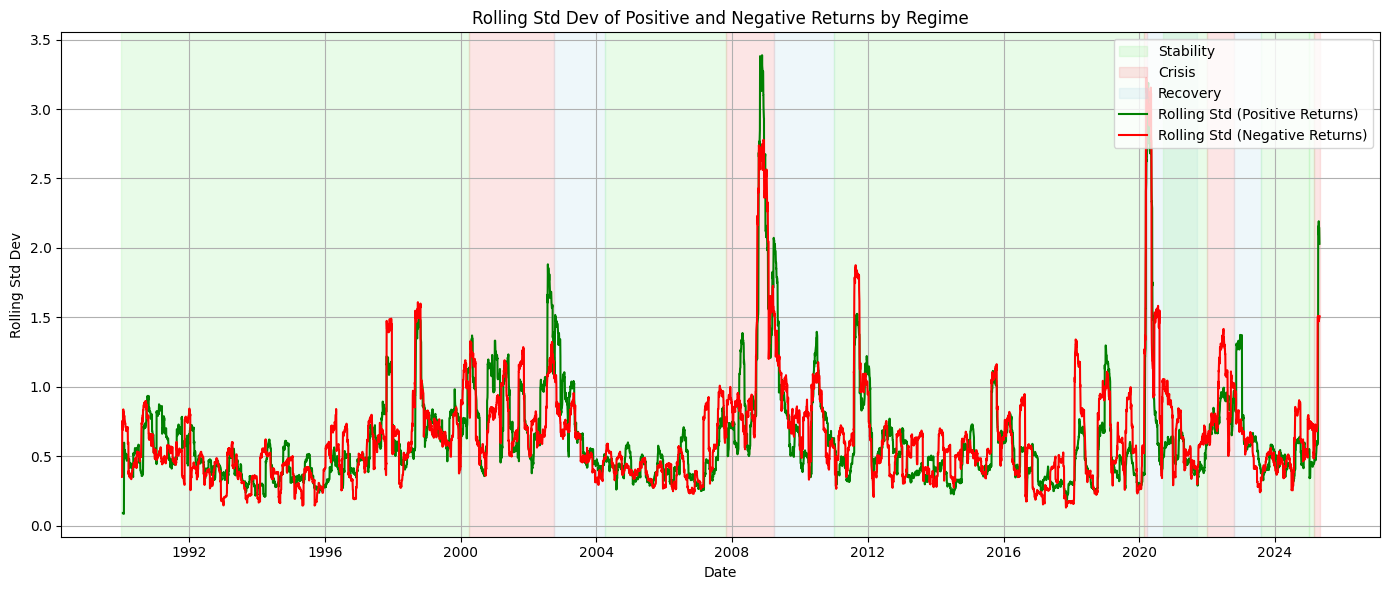

In [ ]:
import matplotlib.pyplot as plt

#Volatility asymmetry doesn't appear randomly, clusters within regimes, justifying regime-switching volatility model --> Doesn't work :(

# Window size in days
window = 40

# Positive and negative returns masks
returns = df["Return"]
#rolling_std_pos = returns.where(returns > 0).rolling(window).std()
#rolling_std_neg = returns.where(returns < 0).rolling(window).std()

rolling_std_pos = returns.where(returns > 0).rolling(window=window, min_periods=5).std()
rolling_std_neg = returns.where(returns < 0).rolling(window=window, min_periods=5).std()


# Prepare plot
fig, ax = plt.subplots(figsize=(14, 6))

# Shade regime periods
regime_colors = {"Stability": "lightgreen", "Crisis": "lightcoral", "Recovery": "lightblue"}
for start, end, regime in [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]:
    ax.axvspan(pd.to_datetime(start), pd.to_datetime(end), color=regime_colors[regime], alpha=0.2, label=regime)

# Plot the rolling std devs
ax.plot(df["Date"], rolling_std_pos, label="Rolling Std (Positive Returns)", color="green")
ax.plot(df["Date"], rolling_std_neg, label="Rolling Std (Negative Returns)", color="red")

# Fix legend to avoid duplicates
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), loc="upper right")

ax.set_title("Rolling Std Dev of Positive and Negative Returns by Regime")
ax.set_ylabel("Rolling Std Dev")
ax.set_xlabel("Date")
ax.grid(True)
plt.tight_layout()
plt.show()


In [12]:
asymmetry_results = []

for regime in sorted(df["Regime"].unique()):
    subset = df[df["Regime"] == regime]["Return"]
    std_pos = subset[subset > 0].std()
    std_neg = subset[subset < 0].std()
    ratio = std_neg / std_pos if std_pos != 0 else np.nan
    asymmetry_results.append((regime, std_pos, std_neg, ratio))

pd.DataFrame(asymmetry_results, columns=["Regime", "Std_Pos", "Std_Neg", "Asymmetry_Ratio"])



,Regime,Std_Pos,Std_Neg,Asymmetry_Ratio
0,Crisis,1.441565,1.430131,0.992069
1,Recovery,0.838949,0.795563,0.948285
2,Stability,0.585561,0.659772,1.126735


In [ ]:
#utlise cette vol pour corrélation entre rendements standardisés (divisé par cette vol)
#regarder aussi la corrélation entre rendements non standardisés

def regime_correlation_analysis(df, col1, col2, regime_col="Regime", K=3):
    """
    Computes correlation between two return series (raw and standardized) by regime using regime-aware GARCH volatility.

    Parameters:
    - df: DataFrame with return columns and regime label
    - col1, col2: str, names of return columns (e.g., "SPX Return", "CAC Return")
    - regime_col: name of the regime column (default "Regime")
    - K: number of regimes (default 3)

    Returns:
    - DataFrame with raw and standardized correlations by regime
    """
    
    y1 = df[col1].values
    y2 = df[col2].values
    regimes = df[regime_col].values

    # Fit GARCH to each return series
    fit1 = fit_regime_garch(y1, regimes, K=K)
    fit2 = fit_regime_garch(y2, regimes, K=K)

    map1 = fit1["mapping"]
    map2 = fit2["mapping"]
    rev1 = fit1["reverse_mapping"]
    rev2 = fit2["reverse_mapping"]

    reg1_num = np.array([map1[r] for r in regimes])
    reg2_num = np.array([map2[r] for r in regimes])

    sigma2_1 = compute_sigma2_regime(y1, reg1_num, fit1["params"], rev1)
    sigma2_2 = compute_sigma2_regime(y2, reg2_num, fit2["params"], rev2)

    df = df.copy()
    df["z1"] = y1 / np.sqrt(sigma2_1)
    df["z2"] = y2 / np.sqrt(sigma2_2)

    results = []
    for regime in sorted(np.unique(regimes)):
        sub = df[df[regime_col] == regime]
        raw_corr = sub[col1].corr(sub[col2])
        std_corr = sub["z1"].corr(sub["z2"])
        results.append((regime, raw_corr, std_corr))

    return pd.DataFrame(results, columns=["Regime", f"{col1} vs {col2} Raw Corr", f"{col1} vs {col2} Std Corr"])

| Code       | Sector Name            | Description                                                                                                    |
| ---------- | ---------------------- | -------------------------------------------------------------------------------------------------------------- |
| **S5CONS** | Consumer Staples       | Companies providing essential products (food, beverages, household goods) — e.g., Procter & Gamble, Coca-Cola. |
| **S5ENRS** | Energy                 | Oil, gas, and consumable fuels — e.g., ExxonMobil, Chevron.                                                    |
| **S5HLTH** | Health Care            | Pharmaceuticals, biotechnology, and medical devices — e.g., Johnson & Johnson, Pfizer.                         |
| **S5FINL** | Financials             | Banks, insurance companies, investment services — e.g., JPMorgan, Goldman Sachs.                               |
| **S5UTIL** | Utilities              | Electric, gas, and water utilities — e.g., Duke Energy, NextEra Energy.                                        |
| **S5MATR** | Materials              | Chemical, construction, and packaging materials — e.g., DuPont, International Paper.                           |
| **S5INFT** | Information Technology | Software, hardware, and IT services — e.g., Apple, Microsoft.                                                  |
| **S5INDU** | Industrials            | Transportation, machinery, aerospace, logistics — e.g., Boeing, FedEx.                                         |
| **S5TELS** | Communication Services | Telecom, media, and entertainment — e.g., Google, Meta, Verizon.                                               |
| **S5COND** | Consumer Discretionary | Retail, autos, luxury goods, travel — e.g., Amazon, Nike, Starbucks.                                           |


In [ ]:

#I CHANGED REGIMES SO MAKE UPDATE, BECAUSE MORE DATA HERE
import pandas as pd
import numpy as np
from arch import arch_model

# Load Excel and rename columns
df = pd.read_excel(DATA / "spx_sectors.xlsx", skiprows=0)
df = df[['Dates', 'SPX','S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL','S5MATR','S5INFT','S5INDU','S5TELS','S5COND']]
df.columns = ['Date', 'SPX','S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL','S5MATR','S5INFT','S5INDU','S5TELS','S5COND']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')


# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-07', 'Crisis'),
    ('2025-04-08', '2025-06-18', 'Recovery'),
]

def assign_regime(date):
    for start, end, regime in regime_periods:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end):
            return regime
    return 'Undef'

df['Regime'] = df['Date'].apply(assign_regime)

In [110]:

"""
    Computes correlation between two return series (raw and standardized) by regime using regime-aware GARCH volatility.

    Parameters:
    - df: DataFrame with return columns and regime label
    - col1, col2: str, names of return columns (e.g., "SPX Return", "CAC Return")
    - regime_col: name of the regime column (default "Regime")
    - K: number of regimes (default 3)

    Returns:
    - DataFrame with raw and standardized correlations by regime
"""

df['SPX Return'] = np.log(df['SPX']).diff() * 100
df['S5INDU Return'] = np.log(df['S5INDU']).diff() * 100
df = df.dropna()

result_df = regime_correlation_analysis(df, "SPX Return",'S5INDU Return', regime_col="Regime", K=3)
pd.DataFrame(result_df)



,Regime,SPX Return vs S5INDU Return Raw Corr,SPX Return vs S5INDU Return Std Corr
0,Crisis,0.924022,0.894508
1,Recovery,0.899020,0.880193
2,Stability,0.905540,0.888785


In [ ]:
import pandas as pd
import numpy as np

# Sector indices to loop over
sectors = ['S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL','S5MATR','S5INFT','S5INDU','S5TELS','S5COND']

results = []

for sector in sectors:
    df_temp = df.copy()

    # Compute log returns for SPX and this sector
    df_temp["SPX Return"] = np.log(df_temp["SPX"]).diff() * 100
    df_temp[f"{sector} Return"] = np.log(df_temp[sector]).diff() * 100

    # Drop missing values
    df_temp = df_temp.dropna(subset=["SPX Return", f"{sector} Return", "Regime"])

    # Skip empty slices
    if len(df_temp) < 50:
        print(f"⚠️ Skipping {sector} — not enough data.")
        continue

    try:
        # Run the correlation analysis
        result_df = regime_correlation_analysis(df_temp, "SPX Return", f"{sector} Return", regime_col="Regime", K=3)
        result_df.insert(0, "Sector", sector)
        results.append(result_df)
    except Exception as e:
        print(f"❌ Error with {sector}: {e}")

# Combine results into a final DataFrame
if results:
    final_result_df = pd.concat(results, ignore_index=True)
    print(final_result_df)
else:
    print("❌ No results — check data or regime labels.")


In [127]:
import pandas as pd
import numpy as np

# === PARAMETERS ===
sector_cols = ['S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL','S5MATR','S5INFT','S5INDU','S5TELS','S5COND']
target_col = "SPX"
regime_col = "Regime"
all_cols = [target_col] + sector_cols
K = 3  # Number of regimes

# === Load your DataFrame ===
# df = pd.read_excel(DATA / "spx_sectors.xlsx")  # if not done already
df = df.dropna(subset=["Date", regime_col] + all_cols).copy()
df["Date"] = pd.to_datetime(df["Date"])

# === Compute Log Returns ===
for col in all_cols:
    df[f"{col}_ret"] = np.log(df[col]).diff() * 100

# Drop first row due to diff
df = df.dropna(subset=[f"{col}_ret" for col in all_cols]).copy()

# === Standardize returns ===
for col in all_cols:
    ret = df[f"{col}_ret"]
    df[f"{col}_z"] = (ret - ret.mean()) / ret.std()

# === Compute correlation matrices per regime ===
regimes = ["Crisis", "Recovery", "Stability"]
raw_corr_matrices = {}
std_corr_matrices = {}

for regime in regimes:
    sub = df[df[regime_col] == regime]
    raw_ret_cols = [f"{col}_ret" for col in all_cols]
    std_ret_cols = [f"{col}_z" for col in all_cols]

    raw_corr = sub[raw_ret_cols].corr().round(3)
    std_corr = sub[std_ret_cols].corr().round(3)

    raw_corr.columns = std_corr.columns = all_cols
    raw_corr.index = std_corr.index = all_cols

    raw_corr_matrices[regime] = raw_corr
    std_corr_matrices[regime] = std_corr

# === Example display ===
for regime in regimes:
    print(f"\n=== Raw Correlation Matrix — {regime} ===")
    display(raw_corr_matrices[regime])
    print(f"\n=== Standardized Correlation Matrix — {regime} ===")
    display(std_corr_matrices[regime])



=== Raw Correlation Matrix — Crisis ===


,SPX,S5CONS,S5ENRS,S5HLTH,S5FINL,S5UTIL,S5MATR,S5INFT,S5INDU,S5TELS,S5COND
SPX,1.000,0.710,0.704,0.767,0.862,0.666,0.816,0.852,0.924,0.804,0.903
S5CONS,0.710,1.000,0.565,0.761,0.616,0.662,0.643,0.411,0.675,0.559,0.626
S5ENRS,0.704,0.565,1.000,0.607,0.584,0.630,0.732,0.449,0.668,0.515,0.570
S5HLTH,0.767,0.761,0.607,1.000,0.641,0.652,0.637,0.489,0.705,0.598,0.646
S5FINL,0.862,0.616,0.584,0.641,1.000,0.546,0.706,0.624,0.808,0.658,0.783
S5UTIL,0.666,0.662,0.630,0.652,0.546,1.000,0.596,0.424,0.621,0.521,0.540
S5MATR,0.816,0.643,0.732,0.637,0.706,0.596,1.000,0.584,0.828,0.613,0.753
S5INFT,0.852,0.411,0.449,0.489,0.624,0.424,0.584,1.000,0.742,0.676,0.746
S5INDU,0.924,0.675,0.668,0.705,0.808,0.621,0.828,0.742,1.000,0.699,0.854
S5TELS,0.804,0.559,0.515,0.598,0.658,0.521,0.613,0.676,0.699,1.000,0.739



=== Standardized Correlation Matrix — Crisis ===


,SPX,S5CONS,S5ENRS,S5HLTH,S5FINL,S5UTIL,S5MATR,S5INFT,S5INDU,S5TELS,S5COND
SPX,1.000,0.710,0.704,0.767,0.862,0.666,0.816,0.852,0.924,0.804,0.903
S5CONS,0.710,1.000,0.565,0.761,0.616,0.662,0.643,0.411,0.675,0.559,0.626
S5ENRS,0.704,0.565,1.000,0.607,0.584,0.630,0.732,0.449,0.668,0.515,0.570
S5HLTH,0.767,0.761,0.607,1.000,0.641,0.652,0.637,0.489,0.705,0.598,0.646
S5FINL,0.862,0.616,0.584,0.641,1.000,0.546,0.706,0.624,0.808,0.658,0.783
S5UTIL,0.666,0.662,0.630,0.652,0.546,1.000,0.596,0.424,0.621,0.521,0.540
S5MATR,0.816,0.643,0.732,0.637,0.706,0.596,1.000,0.584,0.828,0.613,0.753
S5INFT,0.852,0.411,0.449,0.489,0.624,0.424,0.584,1.000,0.742,0.676,0.746
S5INDU,0.924,0.675,0.668,0.705,0.808,0.621,0.828,0.742,1.000,0.699,0.854
S5TELS,0.804,0.559,0.515,0.598,0.658,0.521,0.613,0.676,0.699,1.000,0.739



=== Raw Correlation Matrix — Recovery ===


,SPX,S5CONS,S5ENRS,S5HLTH,S5FINL,S5UTIL,S5MATR,S5INFT,S5INDU,S5TELS,S5COND
SPX,1.000,0.763,0.665,0.786,0.835,0.661,0.864,0.896,0.899,0.749,0.906
S5CONS,0.763,1.000,0.484,0.712,0.593,0.640,0.656,0.598,0.698,0.544,0.646
S5ENRS,0.665,0.484,1.000,0.501,0.674,0.460,0.694,0.462,0.709,0.423,0.509
S5HLTH,0.786,0.712,0.501,1.000,0.583,0.590,0.645,0.639,0.673,0.544,0.639
S5FINL,0.835,0.593,0.674,0.583,1.000,0.540,0.801,0.618,0.840,0.518,0.699
S5UTIL,0.661,0.640,0.460,0.590,0.540,1.000,0.600,0.522,0.627,0.469,0.526
S5MATR,0.864,0.656,0.694,0.645,0.801,0.600,1.000,0.699,0.879,0.575,0.754
S5INFT,0.896,0.598,0.462,0.639,0.618,0.522,0.699,1.000,0.720,0.720,0.830
S5INDU,0.899,0.698,0.709,0.673,0.840,0.627,0.879,0.720,1.000,0.587,0.795
S5TELS,0.749,0.544,0.423,0.544,0.518,0.469,0.575,0.720,0.587,1.000,0.685


... (2 outputs left out)


=== Raw Correlation Matrix — Stability ===


,SPX,S5CONS,S5ENRS,S5HLTH,S5FINL,S5UTIL,S5MATR,S5INFT,S5INDU,S5TELS,S5COND
SPX,1.000,0.755,0.624,0.777,0.862,0.527,0.773,0.809,0.906,0.695,0.898
S5CONS,0.755,1.000,0.407,0.691,0.644,0.561,0.571,0.486,0.681,0.551,0.668
S5ENRS,0.624,0.407,1.000,0.402,0.512,0.389,0.607,0.381,0.573,0.378,0.479
S5HLTH,0.777,0.691,0.402,1.000,0.646,0.412,0.542,0.545,0.667,0.495,0.661
S5FINL,0.862,0.644,0.512,0.646,1.000,0.448,0.679,0.598,0.810,0.553,0.759
S5UTIL,0.527,0.561,0.389,0.412,0.448,1.000,0.422,0.287,0.466,0.449,0.422
S5MATR,0.773,0.571,0.607,0.542,0.679,0.422,1.000,0.544,0.796,0.469,0.689
S5INFT,0.809,0.486,0.381,0.545,0.598,0.287,0.544,1.000,0.680,0.506,0.711
S5INDU,0.906,0.681,0.573,0.667,0.810,0.466,0.796,0.680,1.000,0.581,0.819
S5TELS,0.695,0.551,0.378,0.495,0.553,0.449,0.469,0.506,0.581,1.000,0.611



=== Standardized Correlation Matrix — Stability ===


,SPX,S5CONS,S5ENRS,S5HLTH,S5FINL,S5UTIL,S5MATR,S5INFT,S5INDU,S5TELS,S5COND
SPX,1.000,0.755,0.624,0.777,0.862,0.527,0.773,0.809,0.906,0.695,0.898
S5CONS,0.755,1.000,0.407,0.691,0.644,0.561,0.571,0.486,0.681,0.551,0.668
S5ENRS,0.624,0.407,1.000,0.402,0.512,0.389,0.607,0.381,0.573,0.378,0.479
S5HLTH,0.777,0.691,0.402,1.000,0.646,0.412,0.542,0.545,0.667,0.495,0.661
S5FINL,0.862,0.644,0.512,0.646,1.000,0.448,0.679,0.598,0.810,0.553,0.759
S5UTIL,0.527,0.561,0.389,0.412,0.448,1.000,0.422,0.287,0.466,0.449,0.422
S5MATR,0.773,0.571,0.607,0.542,0.679,0.422,1.000,0.544,0.796,0.469,0.689
S5INFT,0.809,0.486,0.381,0.545,0.598,0.287,0.544,1.000,0.680,0.506,0.711
S5INDU,0.906,0.681,0.573,0.667,0.810,0.466,0.796,0.680,1.000,0.581,0.819
S5TELS,0.695,0.551,0.378,0.495,0.553,0.449,0.469,0.506,0.581,1.000,0.611



==== CRISIS ====



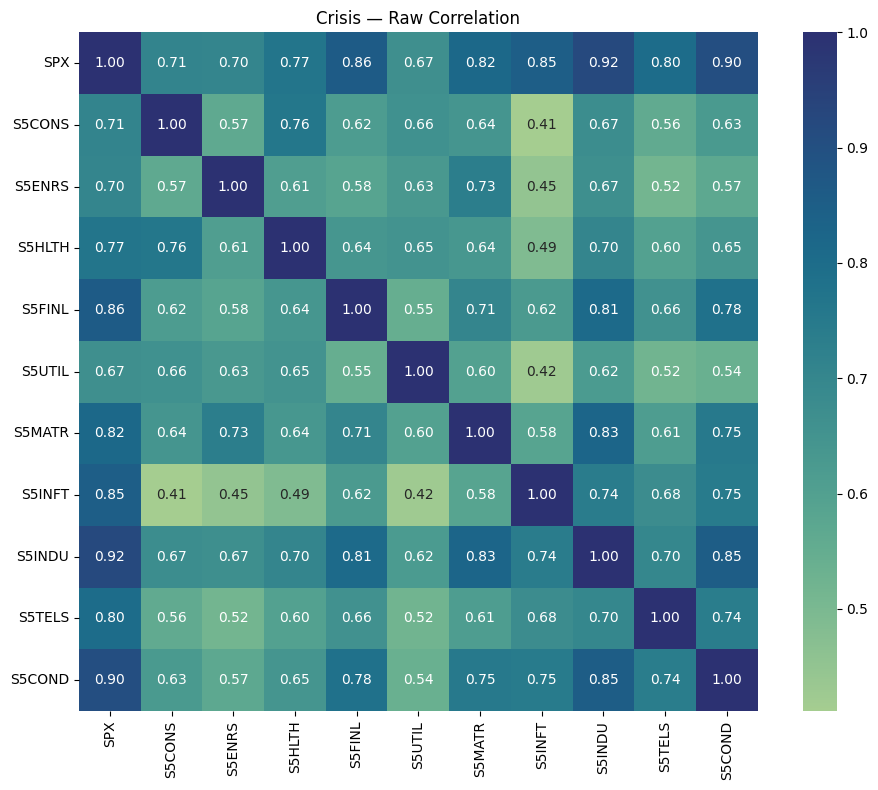

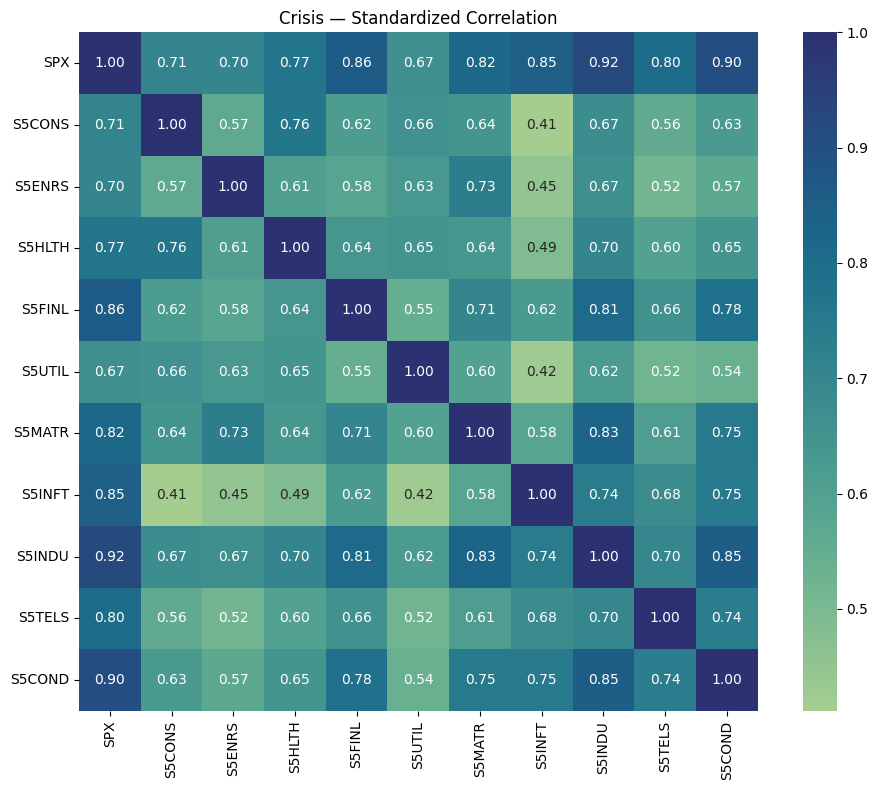


==== RECOVERY ====



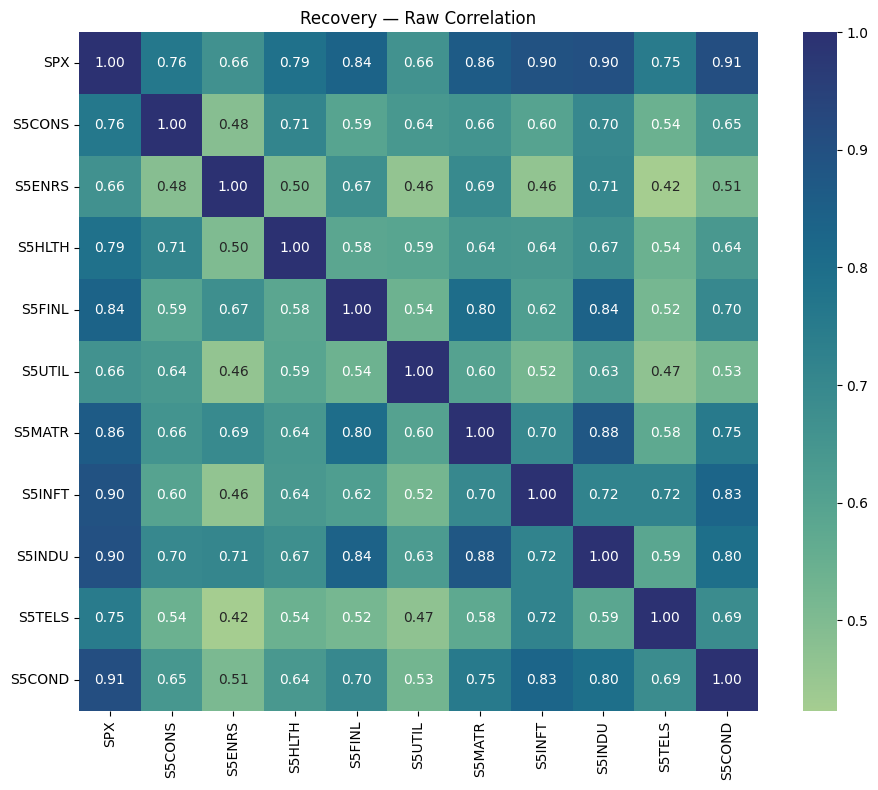

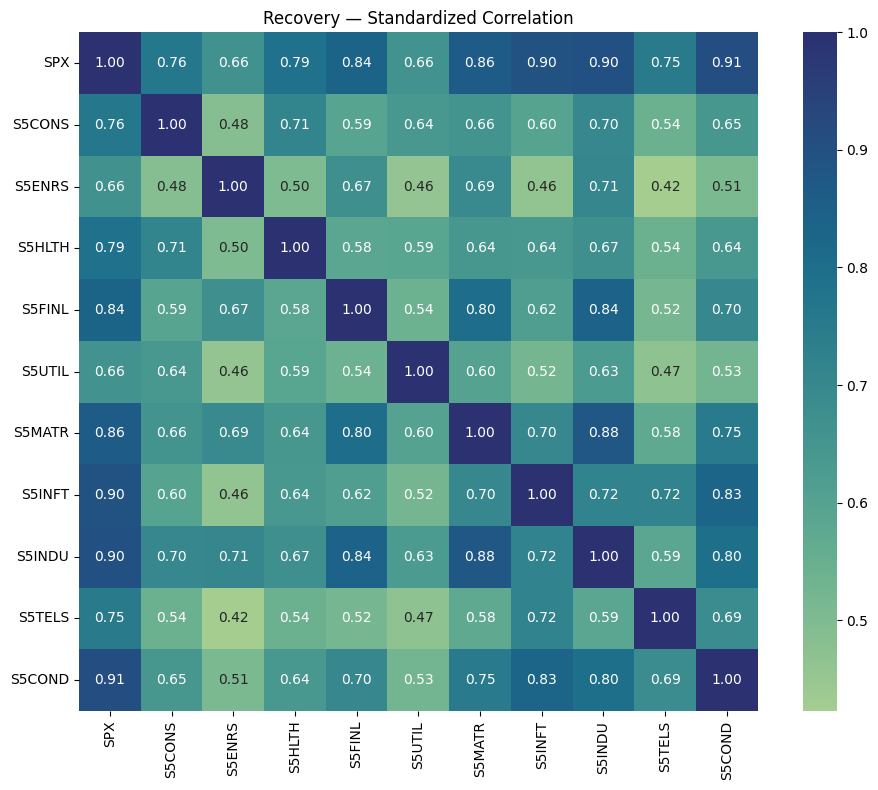


==== STABILITY ====



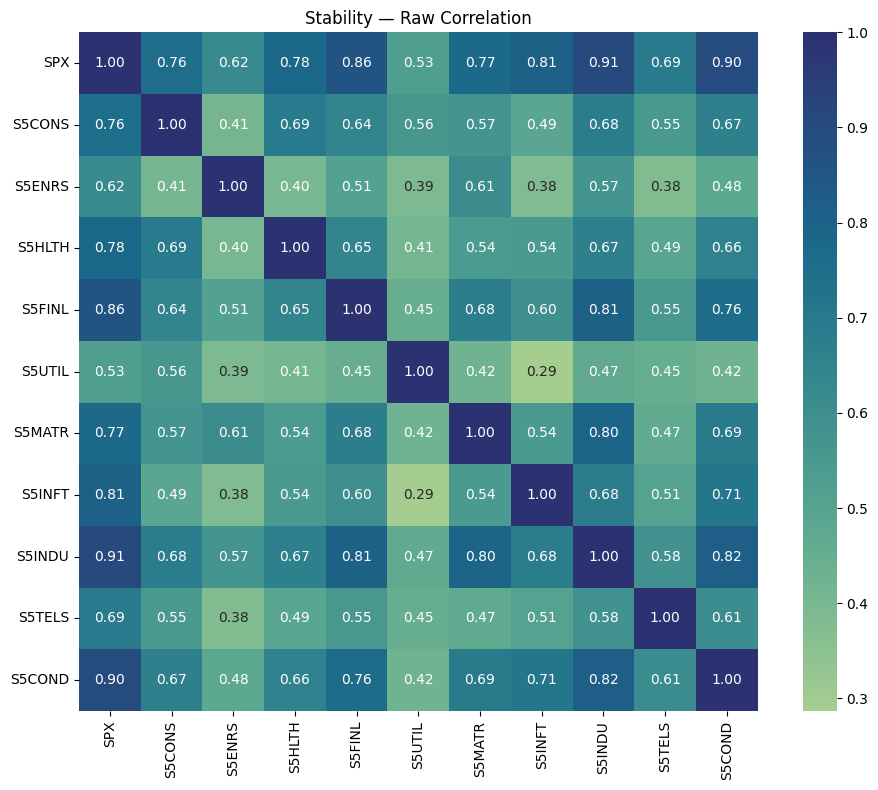

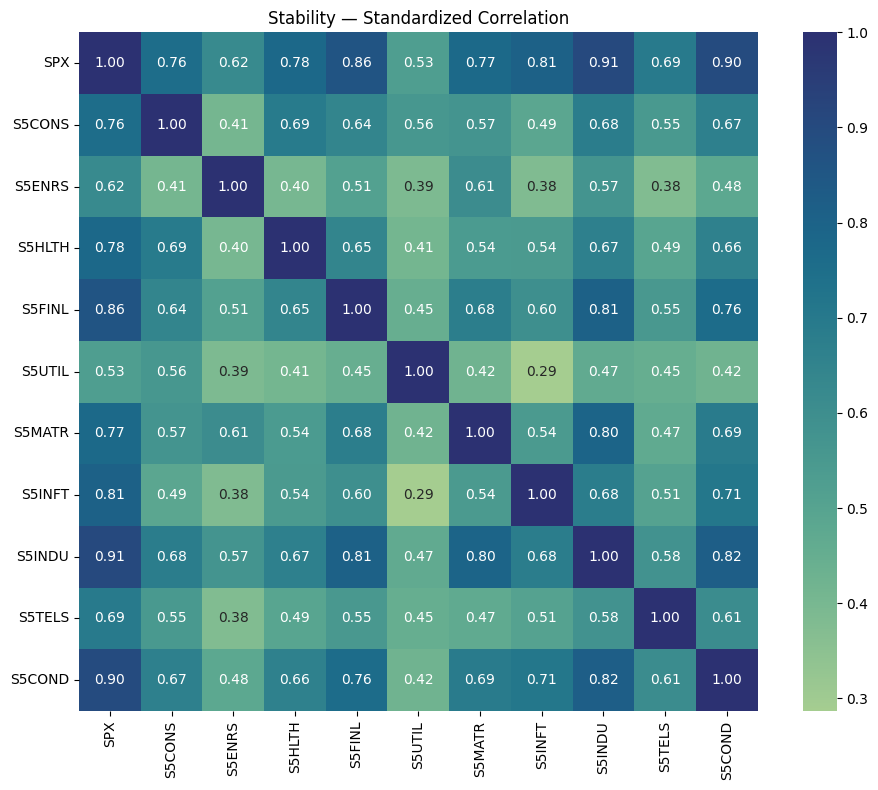

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# === Load & Preprocess ===
# Make sure your dataframe is already loaded as `df` with 'Date' and 'Regime' columns
# and with columns: SPX, S5CONS, S5ENRS, ..., S5COND

sectors = ['SPX','S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL',
           'S5MATR','S5INFT','S5INDU','S5TELS','S5COND']

# Compute log returns
for col in sectors:
    df[f"{col}_ret"] = np.log(df[col]).diff() * 100

df = df.dropna().copy()

# Compute standardized returns
for col in sectors:
    df[f"{col}_z"] = (df[f"{col}_ret"] - df[f"{col}_ret"].mean()) / df[f"{col}_ret"].std()  #ATTENTION UTILISRE LA VOL garch utile
    

# === Correlation Matrices by Regime ===
regimes = ['Crisis', 'Recovery', 'Stability']
corr = {}
std_corr2 = {}

for regime in regimes:
    print(f"\n==== {regime.upper()} ====\n")
    
    sub = df[df['Regime'] == regime].copy()
    
    # Raw return correlation
    raw_corr = sub[[f"{col}_ret" for col in sectors]].corr()
    raw_corr.index = raw_corr.columns = sectors

    # Standardized return correlation
    std_corr = sub[[f"{col}_z" for col in sectors]].corr()
    std_corr.index = std_corr.columns = sectors

    corr[regime] = raw_corr

    std_corr2[regime] = std_corr

    # Plot raw correlation matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(raw_corr, square=True, annot=True, cmap='crest', fmt=".2f")
    plt.title(f"{regime} — Raw Correlation")
    plt.tight_layout()
    plt.show()

    # Plot standardized correlation matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(std_corr, square=True, annot=True, cmap='crest', fmt=".2f")
    plt.title(f"{regime} — Standardized Correlation")
    plt.tight_layout()
    plt.show()





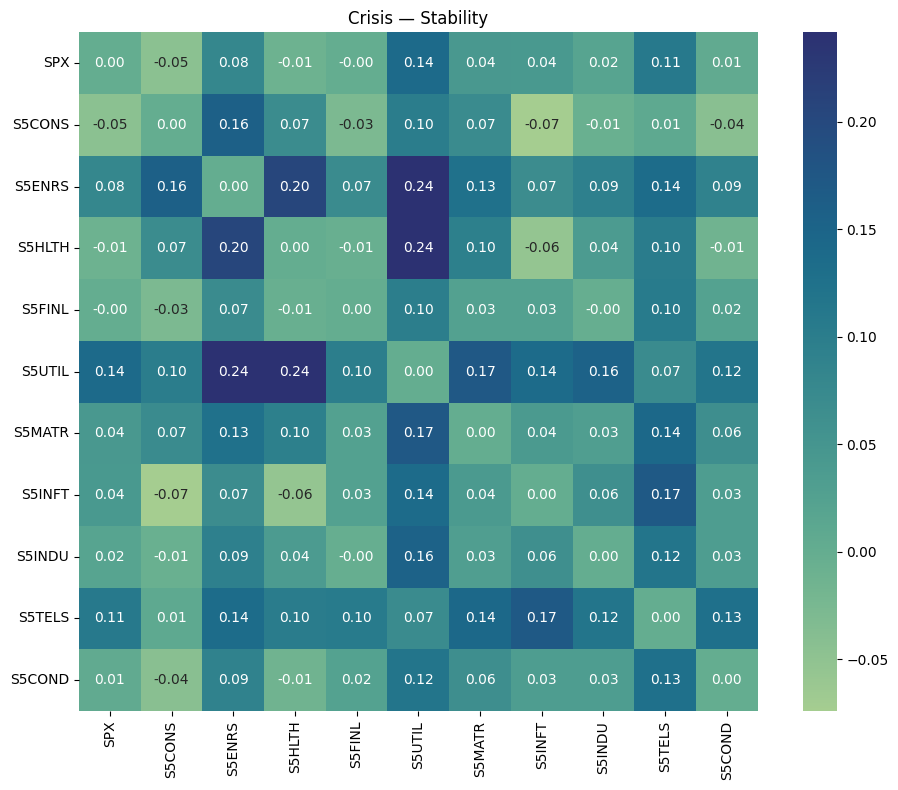

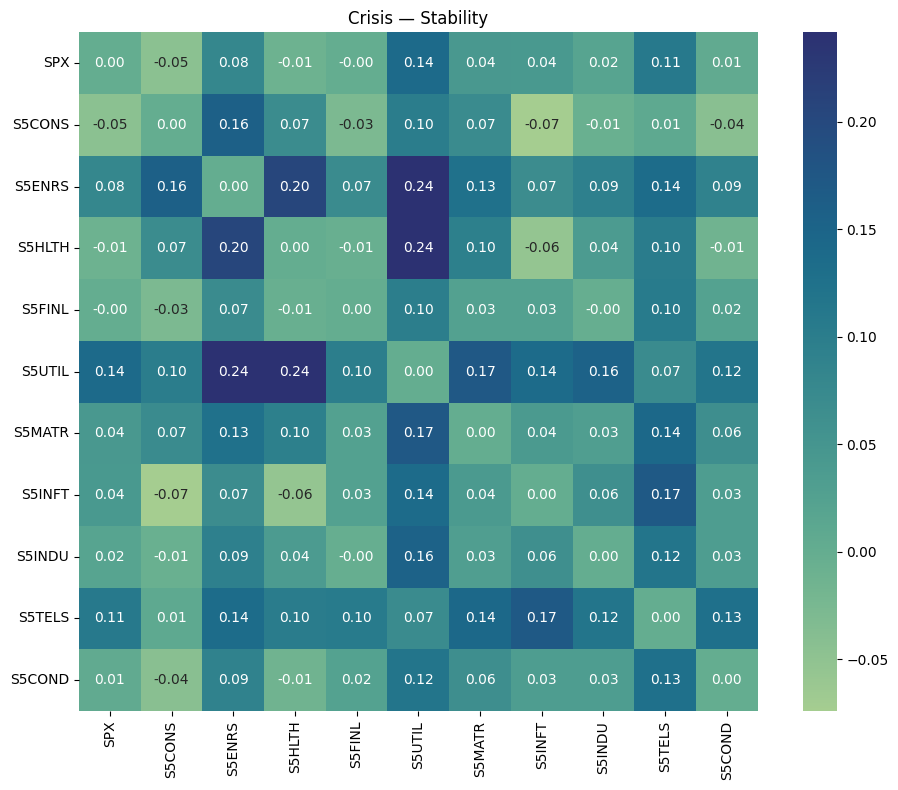

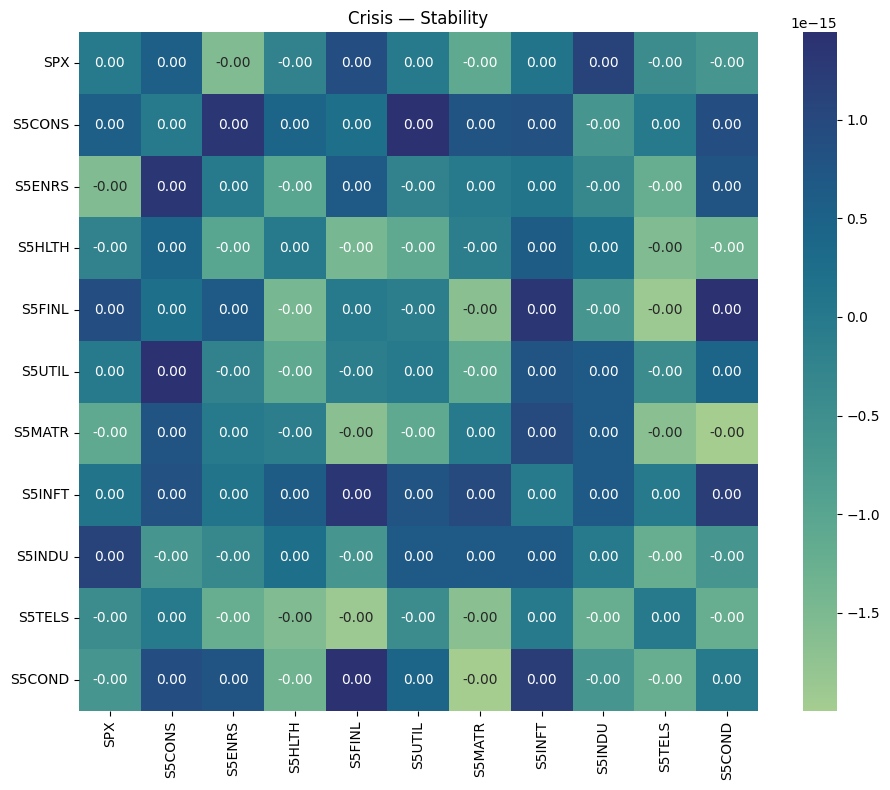

In [142]:
regime1 = 'Crisis'
regime2 = 'Stability'

corr_study = corr[regime1] - corr[regime2]
corr_std_study = std_corr2[regime1] - std_corr2[regime2]
dev_study = std_corr2['Crisis'] - corr['Crisis']

plt.figure(figsize=(10, 8))
sns.heatmap(corr_study, square=True, annot=True, cmap='crest', fmt=".2f")
plt.title(f"{regime1} — {regime2}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_std_study, square=True, annot=True, cmap='crest', fmt=".2f")
plt.title(f"{regime1} — {regime2}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(dev_study, square=True, annot=True, cmap='crest', fmt=".2f")
plt.title(f"{regime1} — {regime2}")
plt.tight_layout()
plt.show()



In [124]:
#Presentation of the tables (Chatgpt)

import pandas as pd
from IPython.display import display, HTML

# Drop rows where all correlation values are missing
clean_df = final_result_df.dropna(subset=[
    col for col in final_result_df.columns if "Corr" in col
], how="all").copy()

# Collect sector tables as HTML strings
sector_tables = []
for sector in sorted(clean_df["Sector"].unique()):
    sub = clean_df[clean_df["Sector"] == sector].copy()
    corr_cols = [c for c in sub.columns if "Corr" in c and sub[c].notna().any()]
    if len(corr_cols) != 2:
        continue
    mini = sub[["Regime"] + corr_cols].dropna(how="all").reset_index(drop=True)
    mini.columns = ["Regime", "Raw Corr", "Std Corr"]
    mini_html = mini.style.set_table_attributes('style="margin: 10px;"')\
                          .set_caption(f"Sector: {sector}")\
                          .format(precision=4)\
                          .to_html()
    sector_tables.append(mini_html)

# Group into rows of 5 tables
rows_html = ""
for i in range(0, len(sector_tables), 5):
    row = sector_tables[i:i+5]
    row_html = '<div style="display:flex; flex-wrap:nowrap;">' + ''.join(row) + '</div>'
    rows_html += row_html

# Display all
display(HTML(rows_html))


,Regime,Raw Corr,Std Corr
0,Crisis,0.9035,0.8750
1,Recovery,0.9063,0.8921
2,Stability,0.8977,0.8856
,Regime,Raw Corr,Std Corr
0,Crisis,0.7102,0.5750
1,Recovery,0.7625,0.7436
2,Stability,0.7556,0.7435
,Regime,Raw Corr,Std Corr
0,Crisis,0.7042,0.5271
1,Recovery,0.6650,0.6624


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio
from scipy.optimize import minimize

    # === PARAMETERS ===
for sector in sectors :
    rolling_window = 80

    # === Ensure returns exist ===
    df_plot = df.copy()

    # Compute log returns
    df_plot["SPX_ret"] = np.log(df_plot["SPX"]).diff() * 100
    df_plot[f"{sector}_ret"] = np.log(df_plot[sector]).diff() * 100

    # Drop NaNs
    df_plot = df_plot.dropna(subset=["SPX_ret", f"{sector}_ret", "Regime", "Date"]).copy()

    # Compute 20-day rolling correlation
    df_plot["RollingCorr"] = (
        df_plot["SPX_ret"].rolling(window=rolling_window)
        .corr(df_plot[f"{sector}_ret"])
    )

    # === Plot with regime coloring ===
    fig, ax = plt.subplots(figsize=(14, 6))

    # Plot rolling correlation
    ax.plot(df_plot["Date"], df_plot["RollingCorr"], label=f"Rolling Corr: SPX vs {sector}", color="black")

    # Add regime background colors
    regime_colors = {
        "Stability": "lightgreen",
        "Crisis": "lightcoral",
        "Recovery": "lightblue"
    }

    for start, end, regime in regime_periods:
        ax.axvspan(pd.to_datetime(start), pd.to_datetime(end),
                color=regime_colors.get(regime, "gray"), alpha=0.25, label=regime)

    # Fix overlapping legend labels
    handles, labels = ax.get_legend_handles_labels()
    unique_labels = dict(zip(labels, handles))
    ax.legend(unique_labels.values(), unique_labels.keys())

    ax.set_title(f"{rolling_window}-Day Rolling Correlation: SPX vs {sector}")
    ax.set_ylabel("Correlation")
    ax.set_xlabel("Date")
    ax.grid(True)
    plt.tight_layout()
    plt.show()


In [122]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio

# === SETTINGS ===
pio.renderers.default = "notebook"  # Or "browser" / "iframe" if needed
target = "SPX"          # Fixed anchor
index = "S5MATR"        # Sector or index to compare against
rolling_window = 40     # Rolling window size in days

# === Compute returns and rolling correlation
df_plot = df.copy()

# Compute log returns
df_plot[f"{target}_ret"] = np.log(df_plot[target]).diff() * 100
df_plot[f"{index}_ret"] = np.log(df_plot[index]).diff() * 100

# Drop rows with missing data
df_plot = df_plot.dropna(subset=[f"{target}_ret", f"{index}_ret", "Regime", "Date"]).copy()

# Compute rolling correlation between standardized returns
df_plot["RollingCorr"] = (
    df_plot[f"{target}_ret"]
    .rolling(window=rolling_window)
    .corr(df_plot[f"{index}_ret"])
)

# Insert NaNs at regime changes to break line segments
df_plot["Regime Shift"] = (df_plot["Regime"] != df_plot["Regime"].shift(1)).astype(int).cumsum()
df_plot["RollingCorrClean"] = df_plot["RollingCorr"]
df_plot["Block ID"] = df_plot["Regime"] + "_" + df_plot["Regime Shift"].astype(str)

# === Plot with Plotly
fig = px.line(
    df_plot,
    x="Date",
    y="RollingCorrClean",
    color="Regime",
    line_group="Block ID",
    title=f"{rolling_window}-Day Rolling Correlation: {target} vs {index}",
    labels={"RollingCorrClean": "Rolling Correlation"},
    template="plotly_white"
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Correlation",
    legend_title="Regime",
    hovermode="x unified",
    font=dict(size=14)
)

fig.show()


In [130]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio

# === SETTINGS ===
pio.renderers.default = "notebook"  # Or "browser" / "iframe" if needed
target = "S5FINL"          # Fixed anchor
index = "S5CONS"        # Sector or index to compare against
rolling_window = 20     # Rolling window size in days

# === Compute returns and rolling correlation
df_plot = df.copy()

# Compute log returns
df_plot[f"{target}_ret"] = np.log(df_plot[target]).diff() * 100
df_plot[f"{index}_ret"] = np.log(df_plot[index]).diff() * 100

# Drop rows with missing data
df_plot = df_plot.dropna(subset=[f"{target}_ret", f"{index}_ret", "Regime", "Date"]).copy()

# Compute rolling correlation between standardized returns
df_plot["RollingCorr"] = (
    df_plot[f"{target}_ret"]
    .rolling(window=rolling_window)
    .corr(df_plot[f"{index}_ret"])
)

# Insert NaNs at regime changes to break line segments
df_plot["Regime Shift"] = (df_plot["Regime"] != df_plot["Regime"].shift(1)).astype(int).cumsum()
df_plot["RollingCorrClean"] = df_plot["RollingCorr"]
df_plot["Block ID"] = df_plot["Regime"] + "_" + df_plot["Regime Shift"].astype(str)

# === Plot with Plotly
fig = px.line(
    df_plot,
    x="Date",
    y="RollingCorrClean",
    color="Regime",
    line_group="Block ID",
    title=f"{rolling_window}-Day Rolling Correlation: {target} vs {index}",
    labels={"RollingCorrClean": "Rolling Correlation"},
    template="plotly_white"
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Correlation",
    legend_title="Regime",
    hovermode="x unified",
    font=dict(size=14)
)

fig.show()


Discu Louis

--> définir les régimes :

fenetre vol et return en rollling into nuage de point pour voir les clusters correspondant aux regimes
window de 20 jours (1mois de taff) essayer pleins de windows pour trouver la window

fois sqrt(252) pour la vol


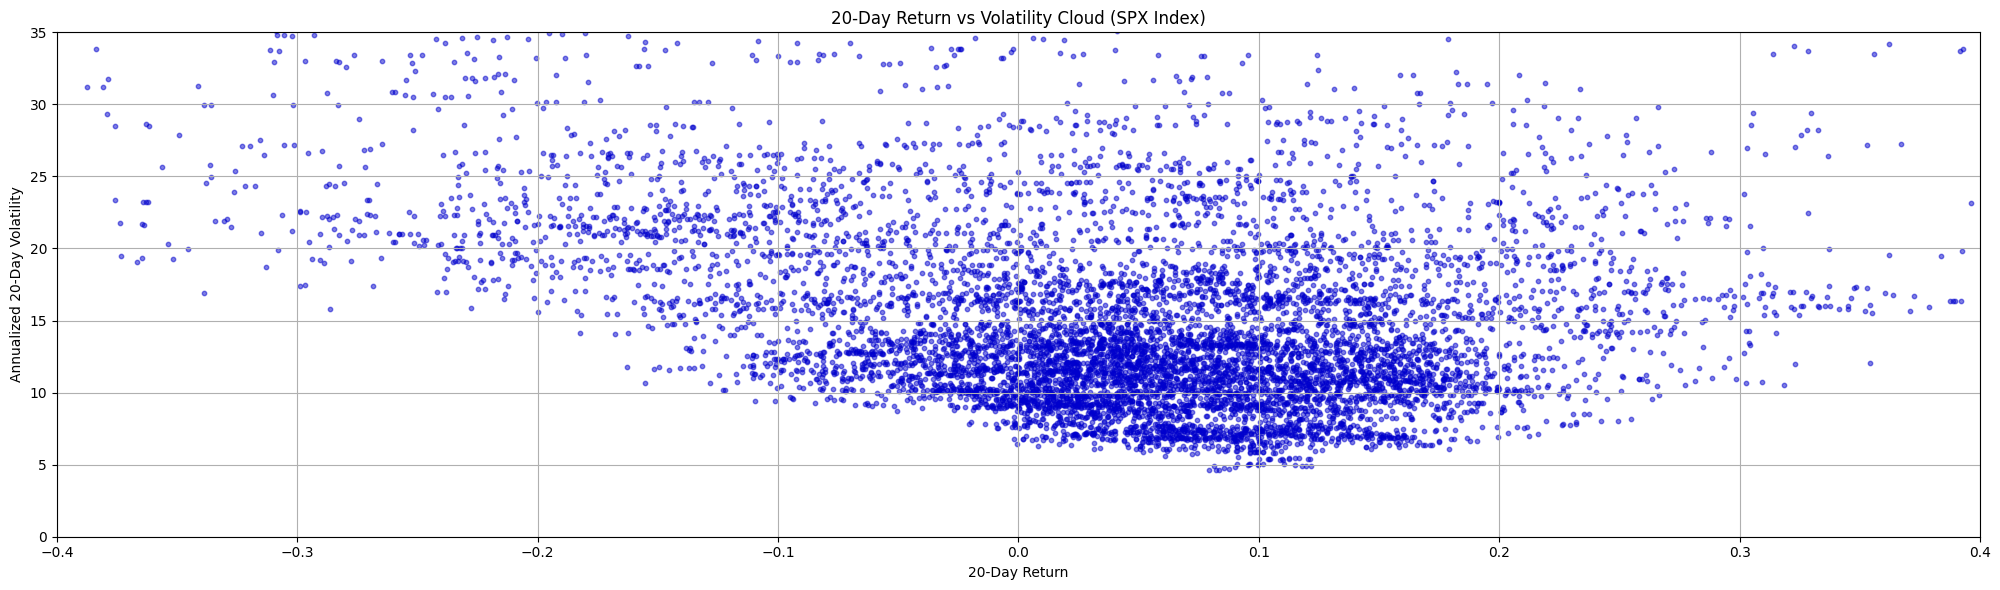

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel(DATA / "data.xlsx", skiprows=2)
df = df[['Dates', 'SPX Index']]
df.columns = ['Date', 'SPX']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')

#for vol
df['Daily Return'] = df['SPX'].pct_change()*100

#return of month
#df['Rolling Return'] = ((df['SPX'] / df['SPX'].shift(20)) - 1) * 100

window = 50

df['Rolling Volatility'] = df['Daily Return'].rolling(window=window).std() * np.sqrt(252)
df['Rolling Return'] = df['Daily Return'].rolling(window=window).sum() / window

df = df.dropna(subset=['Rolling Return', 'Rolling Volatility'])

plt.figure(figsize=(20, 6))
plt.scatter(df['Rolling Return'], df['Rolling Volatility'], alpha=0.5, s=10, color='mediumblue')
plt.xlabel('20-Day Return')
plt.ylabel('Annualized 20-Day Volatility')
plt.title('20-Day Return vs Volatility Cloud (SPX Index)')
plt.grid(True)
plt.tight_layout()
plt.xlim(-0.4,0.4)
plt.ylim(0,35)
plt.show()





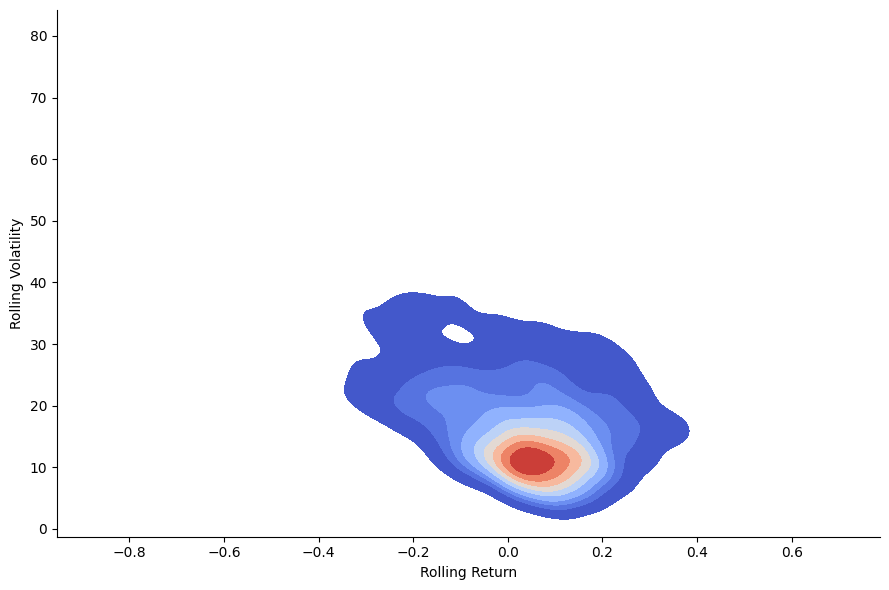

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# 2D KDE Plot
sns.displot(
    data=df,
    x="Rolling Return",
    y="Rolling Volatility",
    kind="kde",
    fill=True,
    thresh=0.05,
    cmap="coolwarm",
    height=6,
    aspect=1.5
)

plt.show()


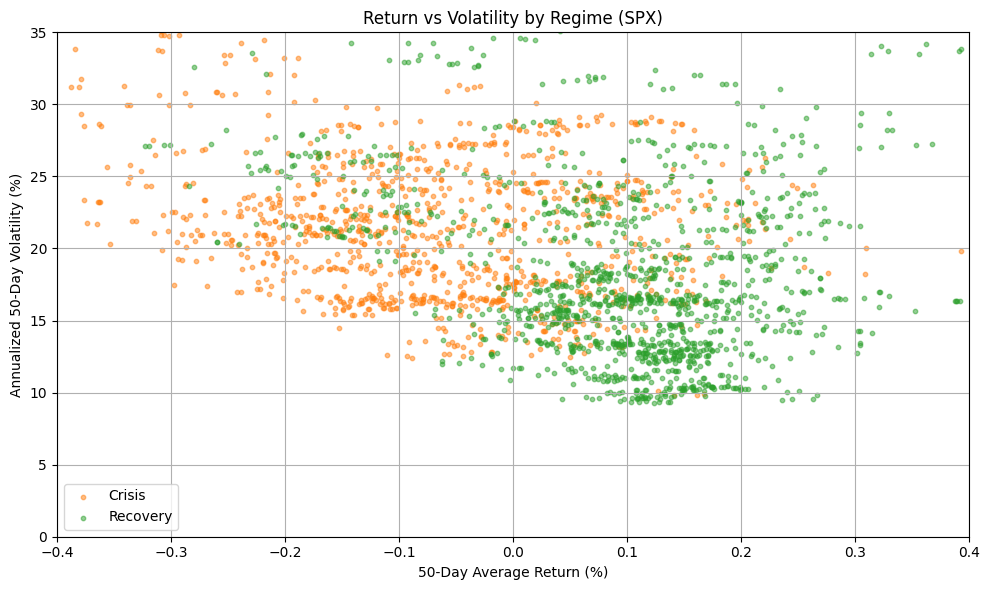

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Step 1: Load SPX Index ===
df = pd.read_excel(DATA / "data.xlsx", skiprows=2)
df = df[['Dates', 'SPX Index']]
df.columns = ['Date', 'SPX']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')

# === Step 2: Define Regime Periods ===
regime_periods = [
    # ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    # ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    # ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    # ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    # ('2023-08-01', '2024-12-31', 'Stability'),
    # ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

# === Step 3: Assign Regimes ===
def assign_regime(date):
    for start, end, regime in regime_periods:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end):
            return regime
        continue

df['Regime'] = df['Date'].apply(assign_regime)

# === Step 4: Compute Rolling Return and Volatility ===
window = 50
df['Daily Return'] = df['SPX'].pct_change() * 100
df['Rolling Volatility'] = df['Daily Return'].rolling(window=window).std() * np.sqrt(252)
df['Rolling Return'] = df['Daily Return'].rolling(window=window).sum() / window

df = df.dropna(subset=['Rolling Return', 'Rolling Volatility'])

# === Step 5: Plot with Regime Coloring ===
plt.figure(figsize=(10, 6))
for regime in df['Regime'].unique():
    subset = df[df['Regime'] == regime]
    plt.scatter(
        subset['Rolling Return'],
        subset['Rolling Volatility'],
        label=regime,
        alpha=0.5,
        s=10
    )

plt.xlabel('50-Day Average Return (%)')
plt.ylabel('Annualized 50-Day Volatility (%)')
plt.title('Return vs Volatility by Regime (SPX)')
plt.grid(True)
plt.xlim(-0.4, 0.4)
plt.ylim(0, 35)
plt.legend()
plt.tight_layout()
plt.show()


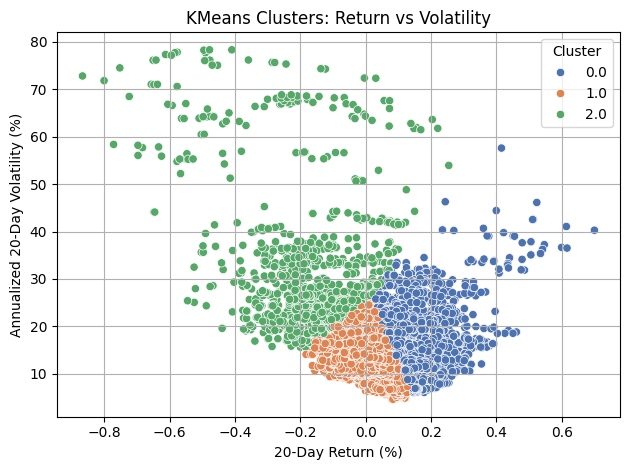

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt


X = df[['Rolling Return', 'Rolling Volatility']].dropna()

X_scaled = StandardScaler().fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=0)
labels = kmeans.fit_predict(X_scaled)
df.loc[X.index, 'Cluster'] = labels

sns.scatterplot(
    data=df.loc[X.index],
    x='Rolling Return',
    y='Rolling Volatility',
    hue='Cluster',
    palette='deep'
)

plt.title("KMeans Clusters: Return vs Volatility")
plt.xlabel("20-Day Return (%)")
plt.ylabel("Annualized 20-Day Volatility (%)")
plt.grid(True)
plt.tight_layout()
plt.show()
